**makemore** is a character-level model

In [3]:
words = open('./makemore/names.txt', 'r').read().splitlines()
words[:10]

['emma',
 'olivia',
 'ava',
 'isabella',
 'sophia',
 'charlotte',
 'mia',
 'amelia',
 'harper',
 'evelyn']

In [6]:
b = {}
for w in words:
    chs = ['<S>'] + list(w) + ['<E>']
    for ch1, ch2 in zip(chs, chs[1:]):
        bigram = (ch1, ch2)
        b[bigram] = b.get(bigram, 0) + 1
        # print(ch1, ch2)

In [16]:
print(sorted(b.items(), key = lambda kv: -kv[1]))

[(('n', '<E>'), 6763), (('a', '<E>'), 6640), (('a', 'n'), 5438), (('<S>', 'a'), 4410), (('e', '<E>'), 3983), (('a', 'r'), 3264), (('e', 'l'), 3248), (('r', 'i'), 3033), (('n', 'a'), 2977), (('<S>', 'k'), 2963), (('l', 'e'), 2921), (('e', 'n'), 2675), (('l', 'a'), 2623), (('m', 'a'), 2590), (('<S>', 'm'), 2538), (('a', 'l'), 2528), (('i', '<E>'), 2489), (('l', 'i'), 2480), (('i', 'a'), 2445), (('<S>', 'j'), 2422), (('o', 'n'), 2411), (('h', '<E>'), 2409), (('r', 'a'), 2356), (('a', 'h'), 2332), (('h', 'a'), 2244), (('y', 'a'), 2143), (('i', 'n'), 2126), (('<S>', 's'), 2055), (('a', 'y'), 2050), (('y', '<E>'), 2007), (('e', 'r'), 1958), (('n', 'n'), 1906), (('y', 'n'), 1826), (('k', 'a'), 1731), (('n', 'i'), 1725), (('r', 'e'), 1697), (('<S>', 'd'), 1690), (('i', 'e'), 1653), (('a', 'i'), 1650), (('<S>', 'r'), 1639), (('a', 'm'), 1634), (('l', 'y'), 1588), (('<S>', 'l'), 1572), (('<S>', 'c'), 1542), (('<S>', 'e'), 1531), (('j', 'a'), 1473), (('r', '<E>'), 1377), (('n', 'e'), 1359), (('l'

In [17]:
import torch

In [30]:
N = torch.zeros((27, 27), dtype=torch.int32)

In [32]:
chars = sorted(list(set(''.join(words))))
stoi = {s:i+1 for i, s in enumerate(chars)}

In [33]:
stoi['.'] = 0

In [37]:
for w in words:
    chs = ['.'] + list(w) + ['.']
    for ch1, ch2 in zip(chs, chs[1:]):
        idx1 = stoi[ch1]
        idx2 = stoi[ch2]
        N[idx1, idx2] += 1
        # print(ch1, ch2)

In [38]:
N

tensor([[   0, 4410, 1306, 1542, 1690, 1531,  417,  669,  874,  591, 2422, 2963,
         1572, 2538, 1146,  394,  515,   92, 1639, 2055, 1308,   78,  376,  307,
          134,  535,  929],
        [6640,  556,  541,  470, 1042,  692,  134,  168, 2332, 1650,  175,  568,
         2528, 1634, 5438,   63,   82,   60, 3264, 1118,  687,  381,  834,  161,
          182, 2050,  435],
        [ 114,  321,   38,    1,   65,  655,    0,    0,   41,  217,    1,    0,
          103,    0,    4,  105,    0,    0,  842,    8,    2,   45,    0,    0,
            0,   83,    0],
        [  97,  815,    0,   42,    1,  551,    0,    2,  664,  271,    3,  316,
          116,    0,    0,  380,    1,   11,   76,    5,   35,   35,    0,    0,
            3,  104,    4],
        [ 516, 1303,    1,    3,  149, 1283,    5,   25,  118,  674,    9,    3,
           60,   30,   31,  378,    0,    1,  424,   29,    4,   92,   17,   23,
            0,  317,    1],
        [3983,  679,  121,  153,  384, 1271,   82,

In [39]:
itos = {i : s for s, i in stoi.items()}
itos

{1: 'a',
 2: 'b',
 3: 'c',
 4: 'd',
 5: 'e',
 6: 'f',
 7: 'g',
 8: 'h',
 9: 'i',
 10: 'j',
 11: 'k',
 12: 'l',
 13: 'm',
 14: 'n',
 15: 'o',
 16: 'p',
 17: 'q',
 18: 'r',
 19: 's',
 20: 't',
 21: 'u',
 22: 'v',
 23: 'w',
 24: 'x',
 25: 'y',
 26: 'z',
 0: '.'}

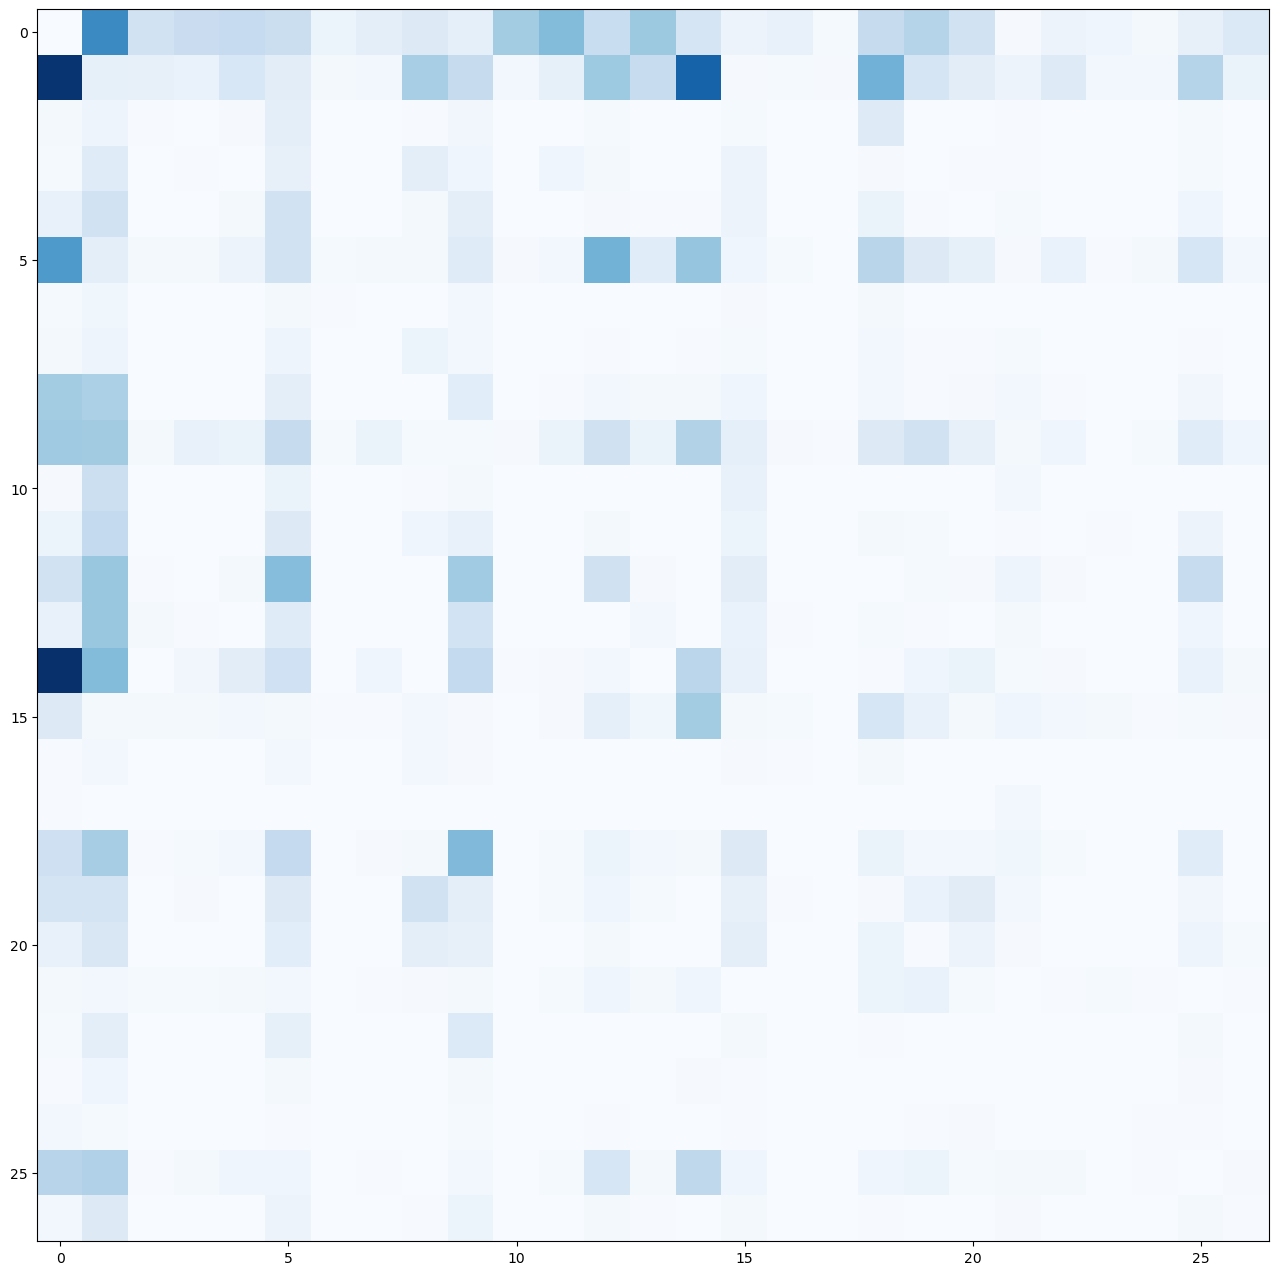

In [40]:
import matplotlib.pyplot as plt
%matplotlib inline

plt.figure(figsize=(16, 16))
plt.imshow(N, cmap='Blues')

Now we have built the dataset array, let's start **sampleing**.

In [41]:
N[0]

tensor([   0, 4410, 1306, 1542, 1690, 1531,  417,  669,  874,  591, 2422, 2963,
        1572, 2538, 1146,  394,  515,   92, 1639, 2055, 1308,   78,  376,  307,
         134,  535,  929], dtype=torch.int32)

In [56]:
p = N[0].float()

p /= p.sum()

p

tensor([0.0000, 0.1377, 0.0408, 0.0481, 0.0528, 0.0478, 0.0130, 0.0209, 0.0273,
        0.0184, 0.0756, 0.0925, 0.0491, 0.0792, 0.0358, 0.0123, 0.0161, 0.0029,
        0.0512, 0.0642, 0.0408, 0.0024, 0.0117, 0.0096, 0.0042, 0.0167, 0.0290])

In [59]:
g = torch.Generator().manual_seed(2147483647)

idx = torch.multinomial(p, num_samples=1, replacement=True, generator=g).item()
itos[idx]

'c'

In [112]:
P = (N+1).float()

P /= P.sum(1, keepdim=True)

In [113]:
g = torch.Generator().manual_seed(2147483647)
for i in range(20):
    idx = 0
    out = []
    while True:
        p = P[idx]
        idx = torch.multinomial(p, num_samples=1, replacement=True, generator=g).item()
        if idx == 0:
            break
        out.append(itos[idx])
    print(''.join(out))

cexze
momasurailezitynn
konimittain
llayn
ka
da
staiyaubrtthrigotai
moliellavo
ke
teda
ka
emimmsade
enkaviyny
ftlspihinivenvorhlasu
dsor
br
jol
pen
aisan
ja


How to judge the quality of the bigram model: defining a *loss* function.

In [114]:
log_likelihood = 0.0
n = 0
for w in words:
    chs = ['.'] + list(w) + ['.']
    for ch1, ch2 in zip(chs, chs[1:]):
        idx1 = stoi[ch1]
        idx2 = stoi[ch2]
        prob = P[idx1, idx2]
        logprob = torch.log(prob)
        log_likelihood += logprob
        n += 1
        # print(f'{ch1}{ch2}: {prob:.4f} {logprob:.4f}')

print(log_likelihood)
nll = -log_likelihood
print(f'{nll=}')
print(f'{nll / n}')

tensor(-559951.5625)
nll=tensor(559951.5625)
2.4543561935424805


GOAL: maximize likelihood of the data w.r.t model parameters (statistical modeling)

**average_negative_log_likelihood** is a good loss function.

So we need to minimize negative_log_likelihood.


Then we decide to use **Neural Network framework** to achieve the same effect.

In [124]:
# create the training set of bigrams (x, y).
xs, ys = [], []

for w in words[:1]:
    chs = ['.'] + list(w) + ['.']
    for ch1, ch2 in zip(chs, chs[1:]):
        idx1 = stoi[ch1]
        idx2 = stoi[ch2]
        N[idx1, idx2] += 1
        xs.append(idx1)
        ys.append(idx2)
        # print(ch1, ch2)

xs = torch.tensor(xs)
ys = torch.tensor(ys)

One-Hot encoding to int n:

create tensor[0,0,0,...,1,0,...] with t_n = 1

In [125]:
import torch.nn.functional as F

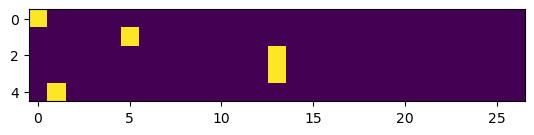

In [ ]:
xenc = F.one_hot(xs, num_classes=27).float()
xenc.shape
plt.imshow(xenc)

In [135]:
W = torch.randn((27, 27))
xenc @ W

tensor([[ 0.9810,  0.7957, -0.3082,  0.5078,  0.1171, -0.7928, -0.2782, -1.1677,
          1.4838, -1.7583, -0.3828,  1.3905,  0.9930, -0.1068, -0.3232,  0.0317,
          0.8003,  1.3185, -0.6398, -0.5108,  0.5432, -1.4675, -1.8182,  1.0747,
         -1.7642,  1.2949, -0.8307],
        [-0.0690, -0.2784, -2.3316,  0.3935, -1.7952, -0.7341,  1.4612,  0.1812,
         -0.2801,  1.2007, -0.1384,  0.7564,  0.4432, -0.7887, -0.3172, -2.0512,
          0.3352, -0.9727, -1.0319, -0.5593,  0.8755, -0.7602,  0.4565,  1.6742,
          0.5728,  1.3809, -0.2906],
        [-0.1363,  0.6733, -0.4329, -1.2961,  0.8162,  1.2136,  1.0242,  0.5956,
          1.7874, -0.7859,  0.2837,  0.2448,  0.4220,  0.8412,  0.6910,  0.6998,
          0.4893, -0.3223, -0.8027,  0.0616, -0.7394, -0.2250,  1.4312,  0.4980,
         -1.0121, -0.7173, -1.7535],
        [-0.1363,  0.6733, -0.4329, -1.2961,  0.8162,  1.2136,  1.0242,  0.5956,
          1.7874, -0.7859,  0.2837,  0.2448,  0.4220,  0.8412,  0.6910,  0.6998

In [142]:
logits = (xenc @ W)
counts = logits.exp()
prob = counts / counts.sum(1, keepdim=True) # This is softmax

In [141]:
prob

tensor([[0.0651, 0.0541, 0.0179, 0.0406, 0.0275, 0.0111, 0.0185, 0.0076, 0.1077,
         0.0042, 0.0167, 0.0981, 0.0659, 0.0219, 0.0177, 0.0252, 0.0544, 0.0913,
         0.0129, 0.0147, 0.0420, 0.0056, 0.0040, 0.0715, 0.0042, 0.0891, 0.0106],
        [0.0243, 0.0197, 0.0025, 0.0386, 0.0043, 0.0125, 0.1124, 0.0312, 0.0197,
         0.0866, 0.0227, 0.0555, 0.0406, 0.0118, 0.0190, 0.0034, 0.0364, 0.0099,
         0.0093, 0.0149, 0.0626, 0.0122, 0.0412, 0.1391, 0.0462, 0.1037, 0.0195],
        [0.0204, 0.0457, 0.0151, 0.0064, 0.0528, 0.0785, 0.0650, 0.0423, 0.1394,
         0.0106, 0.0310, 0.0298, 0.0356, 0.0541, 0.0466, 0.0470, 0.0381, 0.0169,
         0.0105, 0.0248, 0.0111, 0.0186, 0.0976, 0.0384, 0.0085, 0.0114, 0.0040],
        [0.0204, 0.0457, 0.0151, 0.0064, 0.0528, 0.0785, 0.0650, 0.0423, 0.1394,
         0.0106, 0.0310, 0.0298, 0.0356, 0.0541, 0.0466, 0.0470, 0.0381, 0.0169,
         0.0105, 0.0248, 0.0111, 0.0186, 0.0976, 0.0384, 0.0085, 0.0114, 0.0040],
        [0.0107, 0.0093,

In [ ]:
# optimization...


tensor([ 0,  5, 13, 13,  1])

In [170]:
g = torch.Generator().manual_seed(2147483647)
W = torch.randn((27, 27), generator=g, requires_grad=True)

# create the training set of bigrams (x, y).
xs, ys = [], []

for w in words:
    chs = ['.'] + list(w) + ['.']
    for ch1, ch2 in zip(chs, chs[1:]):
        idx1 = stoi[ch1]
        idx2 = stoi[ch2]
        N[idx1, idx2] += 1
        xs.append(idx1)
        ys.append(idx2)
        # print(ch1, ch2)

xs = torch.tensor(xs)
ys = torch.tensor(ys)
num = xs.nelement()


In [185]:
for i in range(1000):
    # forward pass
    xenc = F.one_hot(xs, num_classes=27).float()
    logits = (xenc @ W)
    counts = logits.exp()
    probs = counts / counts.sum(1, keepdim=True) # This is softmax
    loss = -probs[torch.arange(num), ys].log().mean()
    
    # backward pass

    W.grad = None
    loss.backward()

    W.data += -50 * W.grad
    # print(loss.item())


In [189]:

print(loss.item())
g = torch.Generator().manual_seed(2147483647)

for i in range(20):
    idx = 0
    out = []
    while True:
        xenc = F.one_hot(torch.tensor([idx]), num_classes=27).float()
        logits = (xenc @ W)
        counts = logits.exp()
        probs = counts / counts.sum(1, keepdim=True)
        idx = torch.multinomial(probs, num_samples=1, replacement=True, generator=g).item()
        if idx == 0:
            break
        out.append(itos[idx])
    print(''.join(out))

2.455199718475342
cexze
momasurailezitynn
konimittain
llayn
ka
da
staiyaubrtthrigotai
moliellavo
ke
teda
ka
emimmsade
enkaviyny
fobspihinivenvorhlasu
dsor
br
jol
pen
aisan
ja
